# LLM Call Chain: Practice Exercise

Build a summarization chain that progressively condenses information using the same three-step chaining pattern from the lesson.

**What you'll implement:**
- A three-step chain function that generates a detailed explanation, summarizes it, and condenses it to tweet length

**Estimated time:** 10-15 minutes

## Setup

Run the cell below to set up the OpenAI client and the `llm_call` helper function.

In [3]:
# Setup - run this cell first
from groq import Groq

from dotenv import load_dotenv
import os

load_dotenv()

client = Groq(api_key=os.getenv("GROQ_API_KEY"))
total_tokens_used = 0
input_tokens = 0
output_tokens = 0

def llm_call(prompt: str , effort = "low", max_tokens = 4096) -> str:
    """
    Simple wrapper for OpenAI API calls.
    
    Args:
        prompt: The prompt to send to the LLM
        
    Returns:
        The LLM's response text
    """
    global total_tokens_used, input_tokens, output_tokens

    response = client.chat.completions.create(
        model="openai/gpt-oss-20b",
        messages=[{"role": "user", "content": prompt}],  reasoning_effort=effort, max_completion_tokens=max_tokens 
    )
    usage = response.usage                          # token counts for THIS call
    input_tokens += usage.prompt_tokens             # tokens sent to the model (running total)
    output_tokens += usage.completion_tokens        # tokens the model produced, thinking + answer (running total)
    total_tokens_used += usage.total_tokens         # input + output for this call (running total)
    print(f"[this call: in={usage.prompt_tokens}, out={usage.completion_tokens}, total={usage.total_tokens}]")
    return response.choices[0].message.content


print("Setup complete!")

Setup complete!


## Your Task

You will build a **summarization chain** that takes a topic and:

1. **Explains** the topic in detail (3 paragraphs)
2. **Summarizes** the explanation to exactly 3 sentences
3. **Condenses** the summary to a single tweet (280 characters or less)

**Input:** A string describing a topic (e.g., "quantum computing", "photosynthesis", "blockchain")

**Output:** A dictionary with three keys:
- `"explanation"`: A detailed 3-paragraph explanation of the topic (string)
- `"summary"`: A 3-sentence summary of the explanation (string)
- `"tweet"`: A single tweet (280 chars max) condensing the summary (string)

Each step should use `llm_call()` and pass the output from the previous step as context.

## Implementation

Complete the function below by implementing the three-step chain.

In [8]:


def summarization_chain(topic: str) -> dict:
    """
    A three-step chain that progressively condenses information about a topic.

    Args:
        topic: A topic to explain and summarize
               (e.g., "machine learning", "climate change", "DNA")

    Returns:
        A dictionary with keys:
        - "explanation": A detailed 3-paragraph explanation of the topic
        - "summary": A 3-sentence summary of the explanation
        - "tweet": A single tweet (280 chars or less) condensing the summary
    """

    # Step 1: detailed explanation (exactly 3 paragraphs)
    explanation = llm_call(f"Explain the topic '{topic}' in exactly 3 paragraphs."
                           f"Use plain text only, no LaTeX or markdown.")

    # Step 2: 3-sentence summary of the explanation
    summary = llm_call(
        f"Summarise the following explanation in exactly 3 sentences. "
        f"Each sentence must be short (under 25 words) and end with a period. "
        f"Be technically precise. "
        f"Output only the summary.\n\n{explanation}"
     
    )

    # Step 3: condense the summary to a tweet (280 chars or less)
    tweet = llm_call(
        f"Condense this summary into ONE complete, grammatical sentence of at most 28 words. "
        f"Write it in a punchy, easy-to-read style."
        f"End with exactly one relevant hashtag. "
        f"Plain text, output only the tweet.\n\n{summary}",
        effort="low",
        max_tokens=8192,
    )

    # ---- paste the hashtag safety net here ----
    import re  # regular expressions, used to search and clean text

    filler = {"and", "or", "but", "the", "a", "an", "of", "in", "on",
          "for", "to", "with", "while", "yet", "as", "at", "by"}  # words a tweet shouldn't end on

    if not re.search(r"#\w+", tweet):                     # True only if the tweet has NO hashtag
        words = [re.sub(r"\W", "", w).capitalize()        # remove symbols from each word, capitalize it
             for w in topic.split()]                  # "quantum computing" -> ['Quantum', 'Computing']
        hashtag = "#" + "".join(words)                    # '#QuantumComputing' (17 characters)
        max_body = 280 - len(hashtag) - 1                 # room for the text: 280 - 17 - 1 = 262

        if len(tweet) > max_body:                         # text too long to fit the hashtag?
            cut = tweet[:max_body].rsplit(" ", 1)[0]      # keep 262 chars, drop the broken last word

            end = max(cut.rfind(". "), cut.rfind("; "))   # position of the last sentence end (-1 if none)
            if end > 120:                                 # a sentence end exists late enough in the text?
                cut = cut[: end + 1]                      # yes: stop at the end of that sentence
            else:
                parts = cut.split()                       # no: split the text into a list of words
                while parts and parts[-1].lower().strip(",;:") in filler:
                    parts.pop()                           # remove trailing filler words like "and", "the"
                cut = " ".join(parts).rstrip(",;:-")      # join the words back, remove trailing punctuation
            tweet = cut                                   # the shortened text



    return {
        "explanation": explanation,
        "summary": summary,
        "tweet": tweet,
    }


print("the summarization chain is ready")

the summarization chain is ready


# Run Your Implementation

Test your chain with the sample task below.

In [9]:
# Run your implementation
result = summarization_chain("quantum computing")

print("=" * 60)
print("STEP 1 - Detailed Explanation:")
print("=" * 60)
print(result["explanation"])

print("\n" + "=" * 60)
print("STEP 2 - 3-Sentence Summary:")
print("=" * 60)
print(result["summary"])

print("\n" + "=" * 60)
print("STEP 3 - Tweet (280 chars):")
print("=" * 60)
print(result["tweet"])
print(f"\nCharacter count: {len(result['tweet'])}")


[this call: in=96, out=370, total=466]
[this call: in=454, out=98, total=552]
[this call: in=184, out=73, total=257]
STEP 1 - Detailed Explanation:
Quantum computing is a paradigm that uses the principles of quantum mechanics to process information. Unlike classical computers that use bits, which exist only in a state of 0 or 1, quantum computers use quantum bits or qubits. Qubits can occupy superpositions of both 0 and 1 simultaneously, allowing a single qubit to encode far more information than a classical bit. When multiple qubits are entangled, their joint state can represent an exponential number of configurations, enabling certain calculations to be performed in parallel that would be infeasible on a classical machine.

The practical power of quantum computers comes from algorithms that exploit superposition, interference, and entanglement. Shor’s algorithm, for example, can factor large integers exponentially faster than the best-known classical methods, threatening modern encry

# Detailed explanation of Hashtag Safety Net 

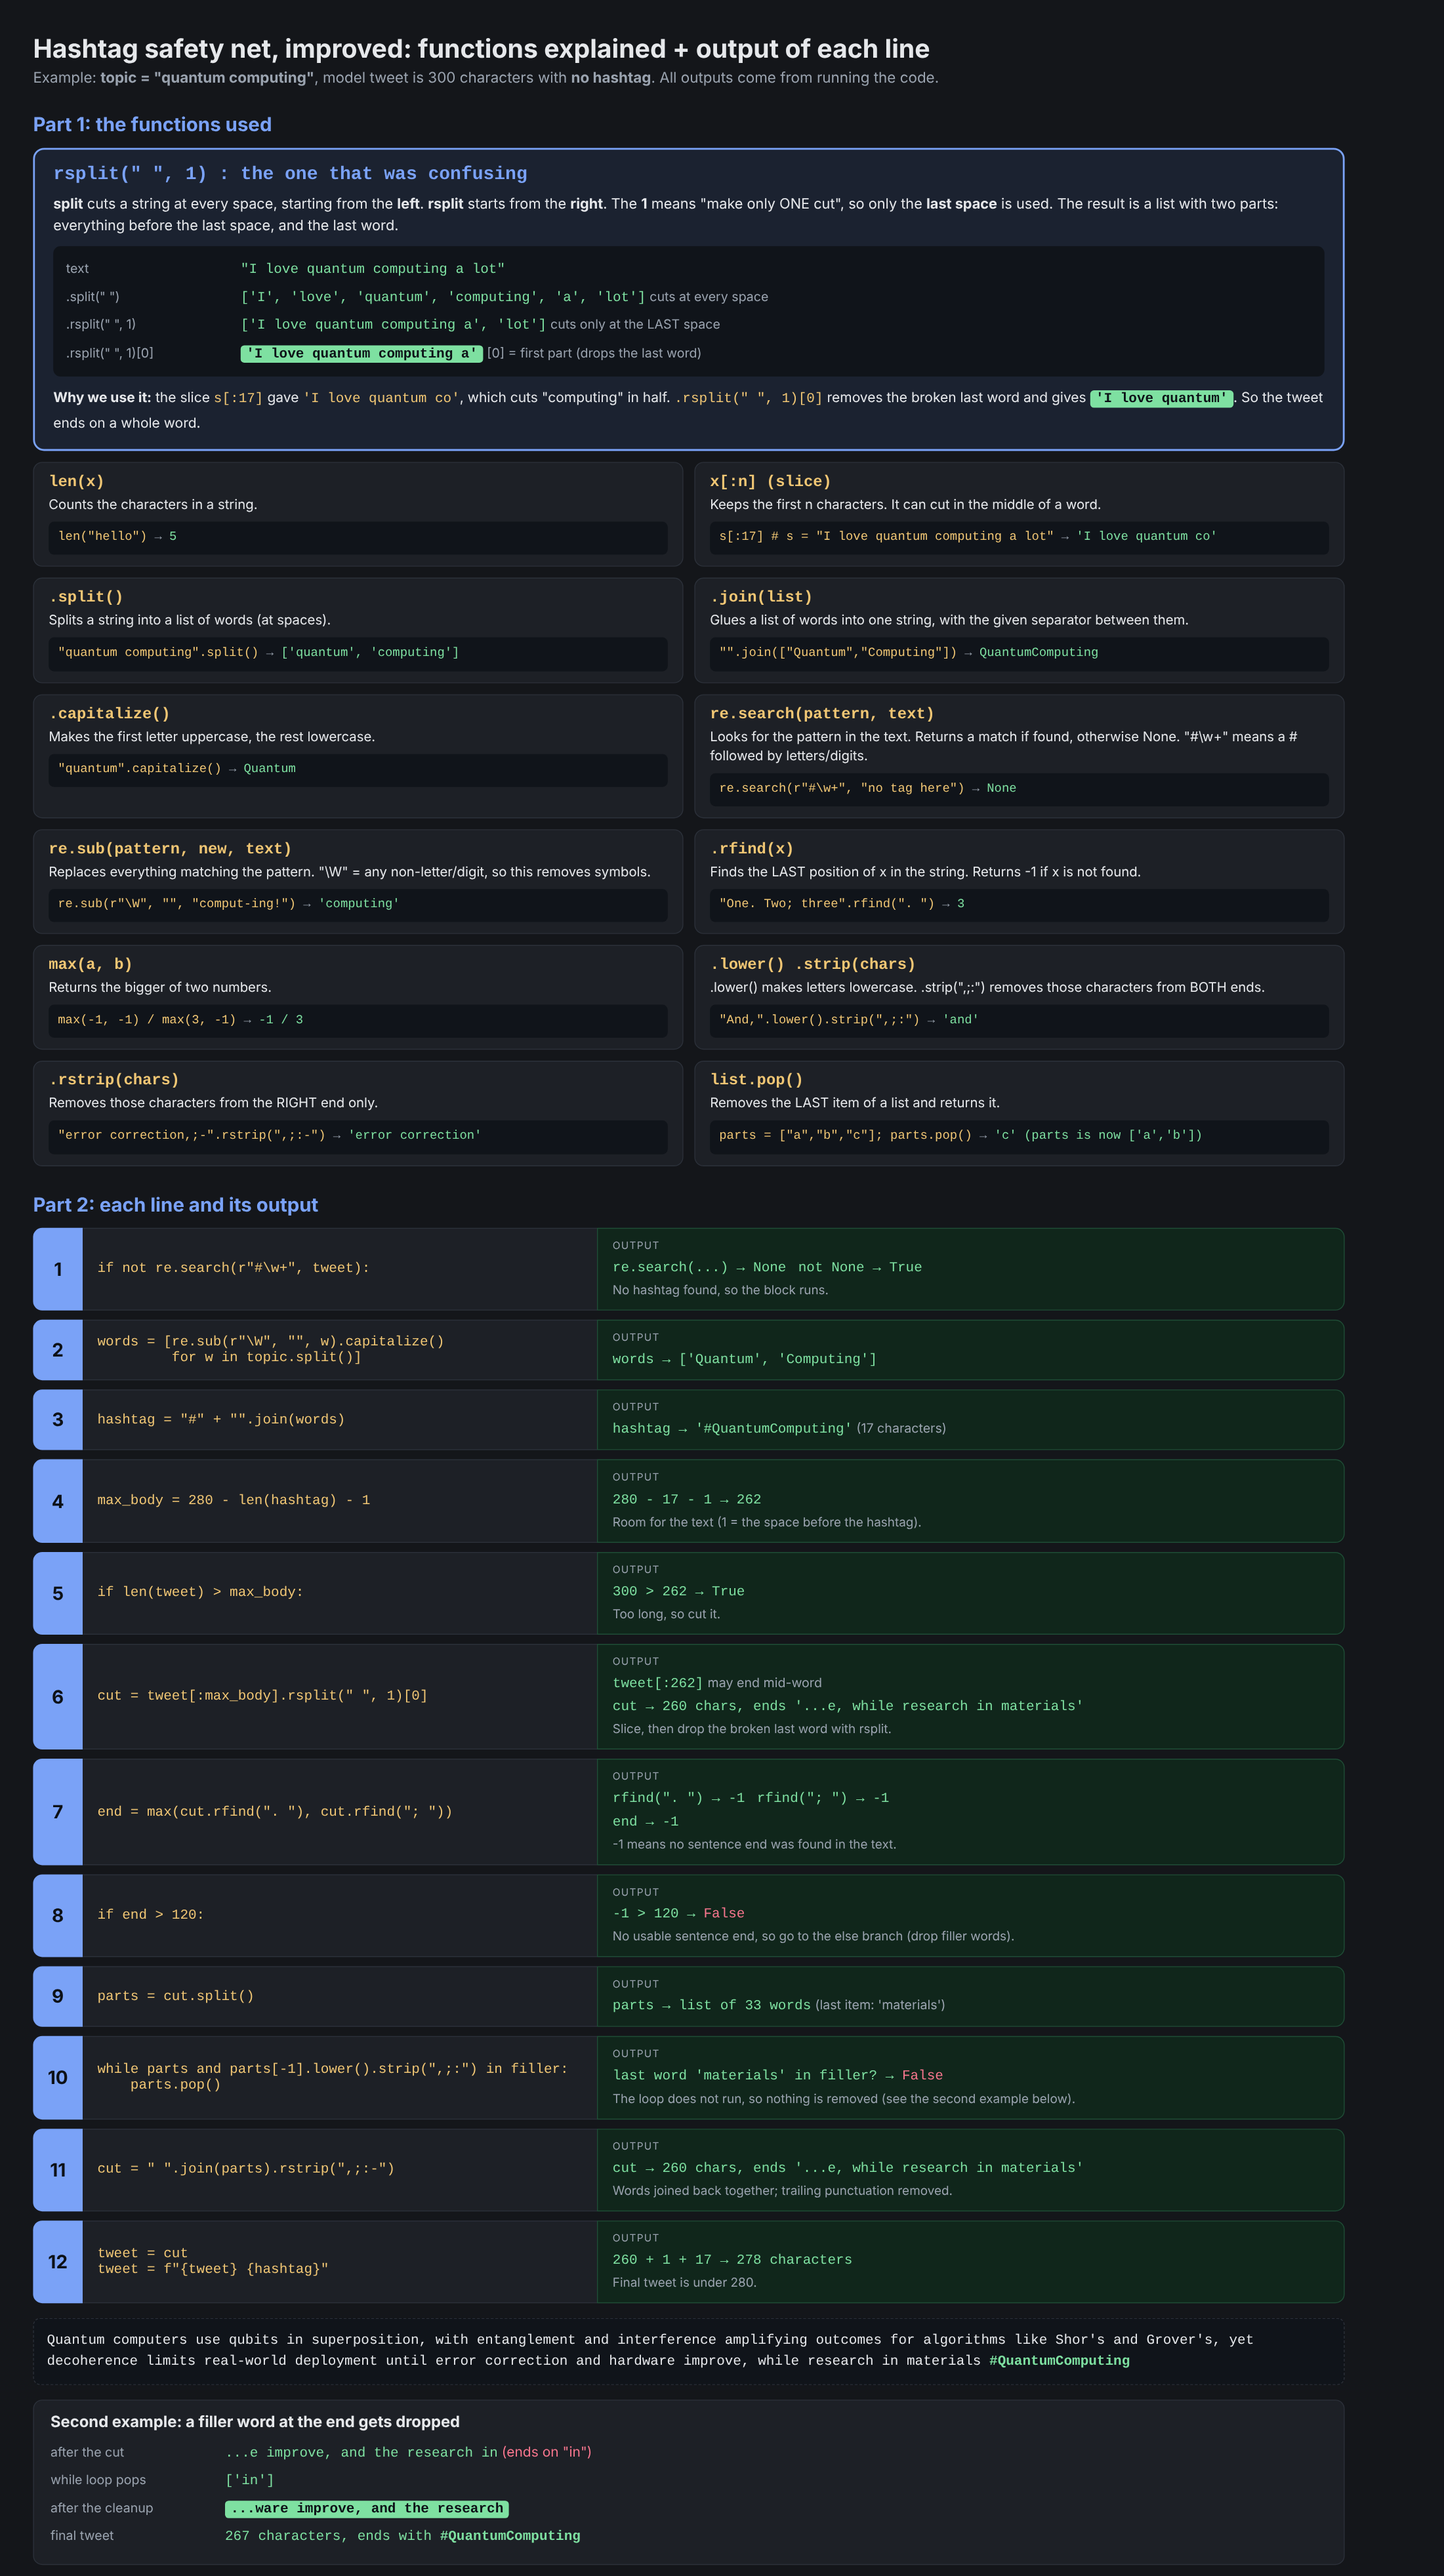

In [12]:
import html
from pathlib import Path
from IPython.display import HTML, display

path = Path("Hashtag Cut Walkthrough.html")      # same folder as the notebook
page = path.read_text(encoding="utf-8")

display(HTML(
    f'<iframe srcdoc="{html.escape(page, quote=True)}" '
    f'width="100%" height="950" style="border:0"></iframe>'
))

d:\env_gitbash\all\Lib\site-packages\IPython\core\display.py:431: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


In [15]:
import re

filler = {"and", "or", "but", "the", "a", "an", "of", "in", "on",
          "for", "to", "with", "while", "yet", "as", "at", "by"}

tweet = "Quantum computers solve hard problems and the research in labs keeps going"
topic = "quantum computing"
LIMIT = 60          # (280 in the real code)
SENTENCE_MIN = 15   # (120 in the real code)

print("tweet =", repr(tweet), "| length:", len(tweet))

if not re.search(r"#\w+", tweet):
    print("1. re.search(...) =", re.search(r"#\w+", tweet), "-> no hashtag, so the block runs")

    words = [re.sub(r"\W", "", w).capitalize() for w in topic.split()]
    print("2. words =", words)

    hashtag = "#" + "".join(words)
    print("3. hashtag =", repr(hashtag), "| length:", len(hashtag))

    max_body = LIMIT - len(hashtag) - 1
    print("4. max_body =", max_body)

    if len(tweet) > max_body:
        print("5. len(tweet) > max_body ->", len(tweet), ">", max_body, "-> True")

        print("6a. tweet[:max_body] =", repr(tweet[:max_body]))
        print("6b. .rsplit(' ', 1) =", tweet[:max_body].rsplit(" ", 1))
        cut = tweet[:max_body].rsplit(" ", 1)[0]
        print("6c. cut =", repr(cut), "| length:", len(cut))

        end = max(cut.rfind(". "), cut.rfind("; "))
        print("7. end =", end)

        if end > SENTENCE_MIN:
            print("8. end > sentence_min -> True")
            cut = cut[: end + 1]
            print("9. cut =", repr(cut))
        else:
            print("8. end > sentence_min -> False, go to else")
            parts = cut.split()
            print("9. parts =", parts)
            while parts and parts[-1].lower().strip(",;:") in filler:
                print("10. last word", repr(parts[-1]), "is filler -> pop")
                parts.pop()
                print("    parts =", parts)
            print("10. last word", repr(parts[-1]), "is not filler -> loop stops")
            cut = " ".join(parts).rstrip(",;:-")
            print("11. cut =", repr(cut), "| length:", len(cut))

        tweet = cut
        print("12. tweet =", repr(tweet))

    tweet = f"{tweet} {hashtag}"
    print("13. final tweet =", repr(tweet), "| length:", len(tweet))

tweet = 'Quantum computers solve hard problems and the research in labs keeps going' | length: 74
1. re.search(...) = None -> no hashtag, so the block runs
2. words = ['Quantum', 'Computing']
3. hashtag = '#QuantumComputing' | length: 17
4. max_body = 42
5. len(tweet) > max_body -> 74 > 42 -> True
6a. tweet[:max_body] = 'Quantum computers solve hard problems and '
6b. .rsplit(' ', 1) = ['Quantum computers solve hard problems and', '']
6c. cut = 'Quantum computers solve hard problems and' | length: 41
7. end = -1
8. end > sentence_min -> False, go to else
9. parts = ['Quantum', 'computers', 'solve', 'hard', 'problems', 'and']
10. last word 'and' is filler -> pop
    parts = ['Quantum', 'computers', 'solve', 'hard', 'problems']
10. last word 'problems' is not filler -> loop stops
11. cut = 'Quantum computers solve hard problems' | length: 37
12. tweet = 'Quantum computers solve hard problems'
13. final tweet = 'Quantum computers solve hard problems #QuantumComputing' | length: 55
